In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully!")


from google.colab import files

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Please upload your agricultural dataset.")

file_name = list(uploaded.keys())[0]

print("\nUploaded File:", file_name)


if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)

elif file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)

else:
    raise ValueError("Please upload an Excel or CSV dataset.")

print("\nDataset Loaded Successfully!")


print("\n========== FIRST FIVE RECORDS ==========")
print(df.head())

print("\n========== DATASET SHAPE ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe(include="all"))


print("\n========== MISSING VALUE ANALYSIS ==========")

missing_values = df.isnull().sum()

print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())


print("\n========== DUPLICATE RECORD ANALYSIS ==========")

duplicate_count = df.duplicated().sum()

print("Duplicate Records Found:", duplicate_count)

df = df.drop_duplicates().copy()

print("Duplicate Records Removed!")

print("Updated Dataset Shape:", df.shape)


print("\n========== HANDLING MISSING VALUES ==========")


numerical_columns = df.select_dtypes(
    include=["number"]
).columns

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns


for column in numerical_columns:

    if df[column].isnull().sum() > 0:

        median_value = df[column].median()

        if pd.isna(median_value):
            median_value = 0

        df[column] = df[column].fillna(median_value)


for column in categorical_columns:

    if df[column].isnull().sum() > 0:

        mode_value = df[column].mode()

        if not mode_value.empty:
            fill_value = mode_value[0]
        else:
            fill_value = "Unknown"

        df[column] = df[column].fillna(fill_value)


print("Missing Values Handled Successfully!")


if "Date" in df.columns:

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    print("\nDate Column Converted Successfully!")


print("\n========== FINAL DATA QUALITY REPORT ==========")

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

print(
    "Remaining Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Remaining Duplicate Records:",
    df.duplicated().sum()
)

print("\nCleaned Dataset Preview:")
print(df.head())



df.to_csv(
    "cleaned_supply_chain_data.csv",
    index=False
)

print("\nCleaned Dataset Saved Successfully!")

print("\n============================================")
print("PART 1 COMPLETED SUCCESSFULLY!")
print("DATA LOADING AND PREPROCESSING COMPLETED!")
print("============================================")

Libraries Imported Successfully!


Saving supply_chain_price_optimization_dataset.xlsx to supply_chain_price_optimization_dataset (2).xlsx

Uploaded File: supply_chain_price_optimization_dataset (2).xlsx

Dataset Loaded Successfully!

========== FIRST FIVE RECORDS ==========
          Batch_ID       Date    Commodity        Source_Mandi  \
0  BATCH-2026-1000 2026-08-01       Tomato          Nashik Hub   
1  BATCH-2026-1001 2026-08-01       Potato          Pune Rural   
2  BATCH-2026-1002 2026-08-01        Onion  Kolar Farm Cluster   
3  BATCH-2026-1003 2026-08-01  Cauliflower           Agra Belt   
4  BATCH-2026-1004 2026-08-02        Apple   Jodhpur Mandi Hub   

     Destination_Market  Distance_KM         Transit_Mode  Transit_Time_Hours  \
0          Mumbai Metro          161  Mini Truck (Shared)                 3.6   
1            Pune Urban           36  Mini Truck (Shared)                 0.8   
2        Bangalore City           69  Standard Open Truck                 1.3   
3             Delhi NCR          213  


PART 2: EXPLORATORY DATA ANALYSIS STARTED

========== DATASET INFORMATION ==========
Dataset Shape: (120, 24)

Available Columns:
['Batch_ID', 'Date', 'Commodity', 'Source_Mandi', 'Destination_Market', 'Distance_KM', 'Transit_Mode', 'Transit_Time_Hours', 'Weather_Condition', 'Shelf_Life_Days', 'Harvest_Quantity_KG', 'Predicted_Demand_KG', 'Farmer_Production_Cost_INR_per_KG', 'Farmer_Fair_Payout_INR_per_KG', 'Farmer_Profit_Margin_Pct', 'Transit_Cost_INR_per_KG', 'Handling_Storage_Cost_INR_per_KG', 'Traditional_Wholesaler_Price_INR', 'Traditional_Retail_Price_INR', 'Optimized_Wholesaler_Price_INR', 'Optimized_Fair_Retail_Price_INR', 'Baseline_Spoilage_Pct', 'Optimized_Spoilage_Pct', 'Consumer_Savings_Pct']

Statistical Summary:
               Batch_ID                 Date Commodity Source_Mandi  \
count               120                  120       120          120   
unique              120                  NaN         6            6   
top     BATCH-2026-1000                  NaN    To

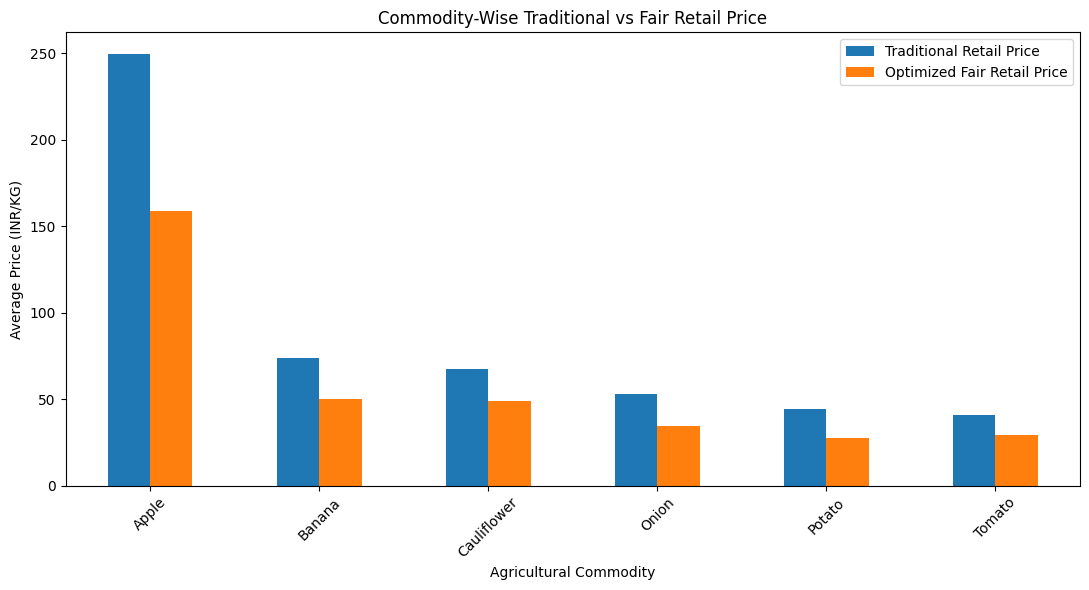


========== DEMAND AND HARVEST ANALYSIS ==========

Average Predicted Demand and Harvest Quantity:
             Predicted_Demand_KG  Harvest_Quantity_KG
Commodity                                            
Apple                    1389.35              1201.45
Banana                   1402.35              1193.20
Cauliflower              1378.10              1243.25
Onion                    1300.35              1100.95
Potato                   1340.15              1237.90
Tomato                   1275.25              1146.10


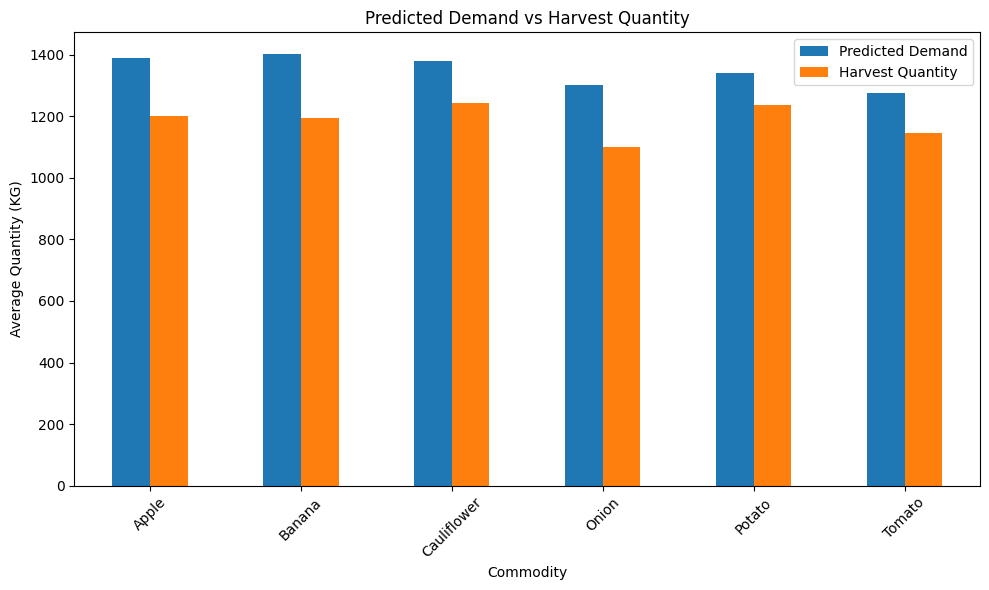


========== TRANSPORTATION COST ANALYSIS ==========

Transportation Cost Summary:
count    120.000000
mean       3.598083
std        1.865819
min        1.200000
25%        1.987500
50%        3.370000
75%        4.477500
max        7.890000
Name: Transit_Cost_INR_per_KG, dtype: float64


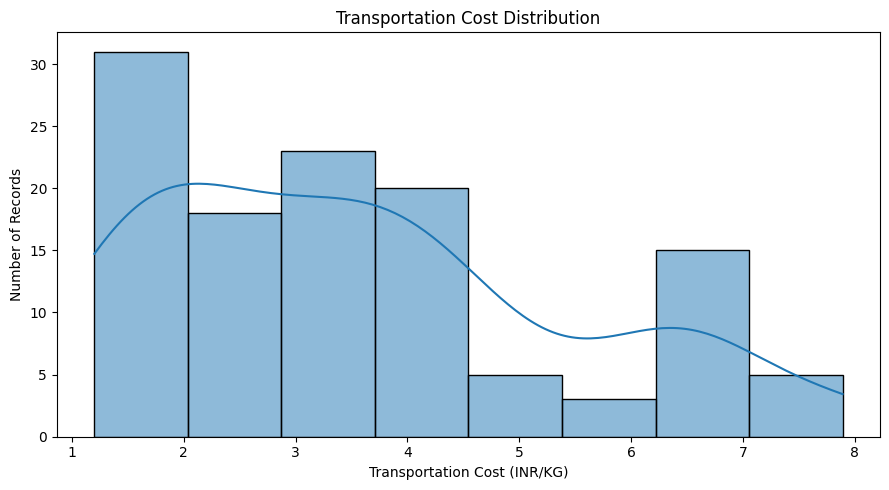


Average Transportation Cost by Mode:
Transit_Mode
Mini Truck (Shared)    3.26
Standard Open Truck    3.28
Refrigerated Van       4.86
Name: Transit_Cost_INR_per_KG, dtype: float64


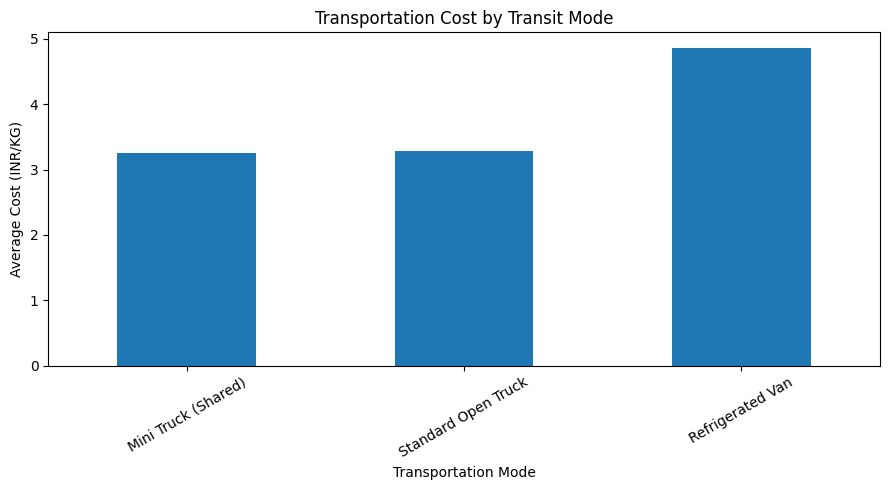


========== MONTHLY PRICE ANALYSIS ==========

Monthly Average Traditional Retail Price:
Month
8    88.1
Name: Traditional_Retail_Price_INR, dtype: float64
Only one month of data is available. A seasonal trend cannot be established.

========== SPOILAGE ANALYSIS ==========

Average Spoilage:
Baseline_Spoilage_Pct     2.14
Optimized_Spoilage_Pct    0.97
dtype: float64


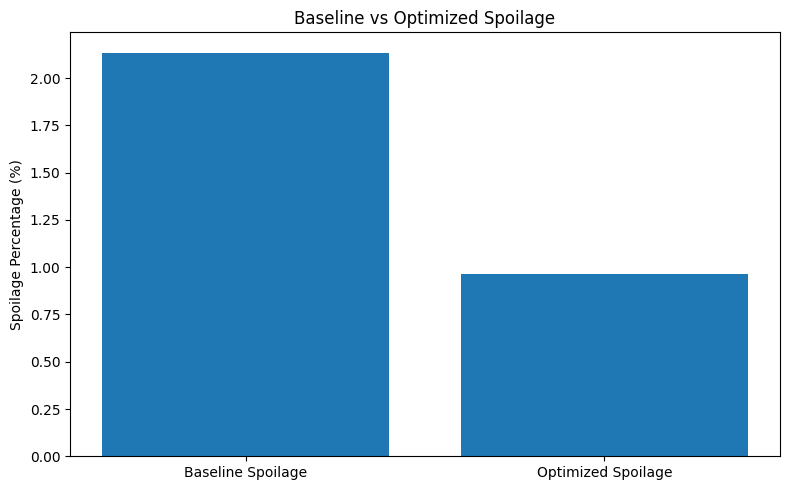


Average Spoilage Reduction: 1.17 percentage points

========== CORRELATION ANALYSIS ==========

Correlation Matrix:
                                   Distance_KM  Transit_Time_Hours  \
Distance_KM                               1.00                0.97   
Transit_Time_Hours                        0.97                1.00   
Shelf_Life_Days                          -0.08               -0.10   
Harvest_Quantity_KG                       0.03                0.04   
Predicted_Demand_KG                       0.04                0.01   
Farmer_Production_Cost_INR_per_KG         0.80                0.75   
Farmer_Fair_Payout_INR_per_KG             0.80                0.75   
Farmer_Profit_Margin_Pct                 -0.05               -0.03   
Transit_Cost_INR_per_KG                   0.94                0.90   
Handling_Storage_Cost_INR_per_KG         -0.02               -0.05   
Traditional_Wholesaler_Price_INR          0.81                0.77   
Traditional_Retail_Price_INR              0

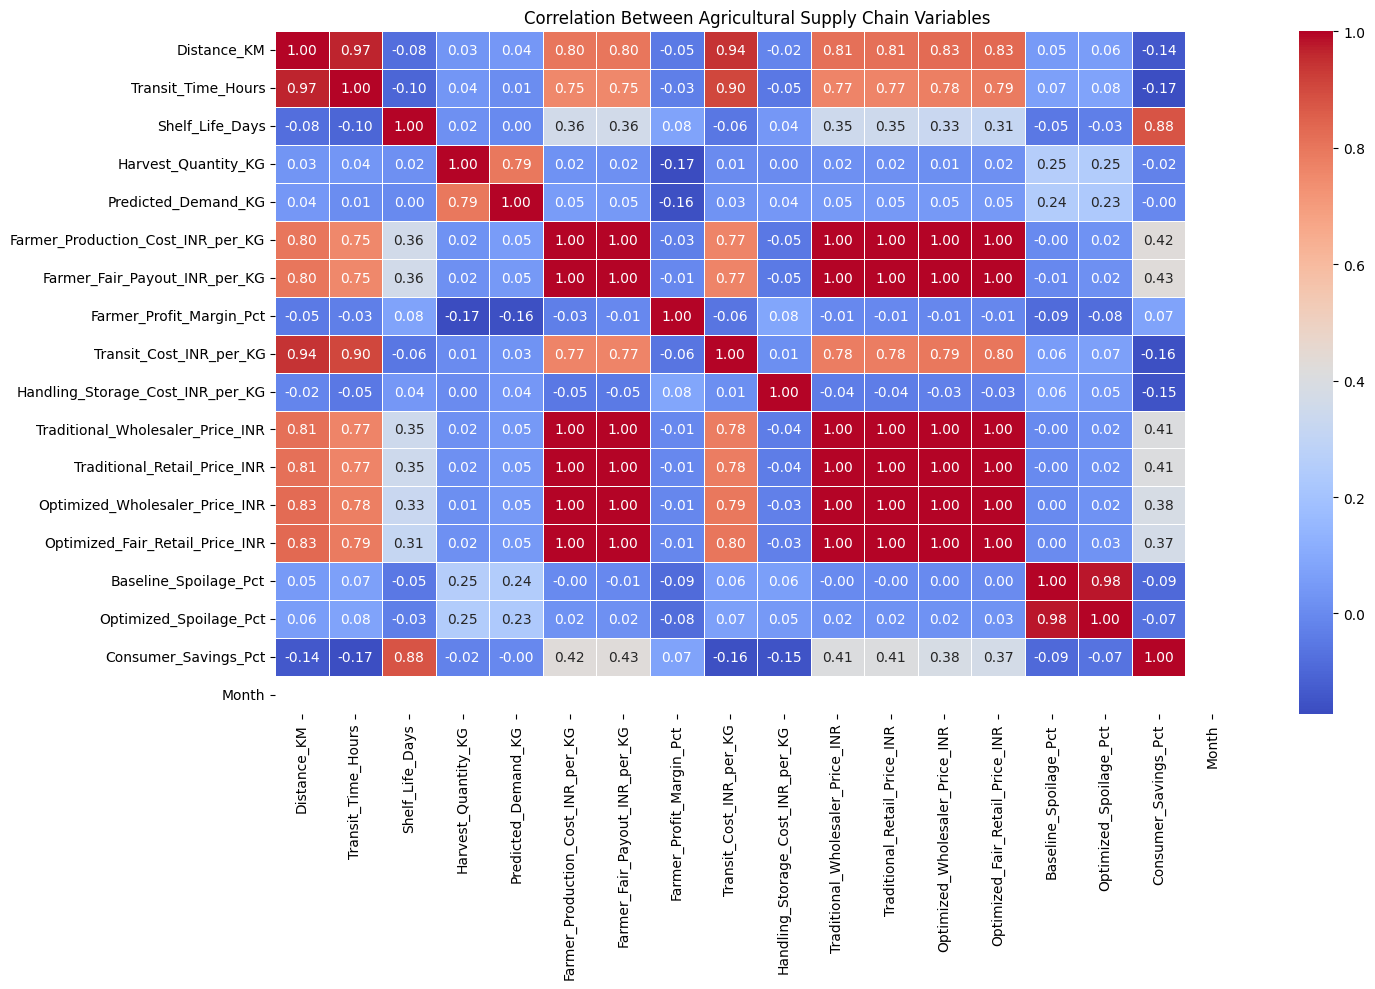


========== IMPORTANT PROJECT OBSERVATIONS ==========
Average Traditional Retail Price: 88.1 INR/KG
Average Optimized Fair Retail Price: 58.19 INR/KG
Average Dataset Demand Estimate: 1347.59 KG
Average Harvest Quantity: 1187.14 KG
Average Transportation Cost: 3.6 INR/KG
Average Baseline Spoilage: 2.14 %
Average Optimized Spoilage: 0.97 %

Note: Correlation indicates association, not necessarily cause and effect.

EDA Dataset Saved Successfully!

PART 2 COMPLETED SUCCESSFULLY!
EXPLORATORY DATA ANALYSIS FINISHED!


In [ ]:
# ============================================================
# PART 2: EXPLORATORY DATA ANALYSIS (EDA)
# PROJECT: SMART AGRICULTURAL SUPPLY CHAIN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("\n============================================")
print("PART 2: EXPLORATORY DATA ANALYSIS STARTED")
print("============================================")


print("\n========== DATASET INFORMATION ==========")

print("Dataset Shape:", df.shape)

print("\nAvailable Columns:")
print(df.columns.tolist())

print("\nStatistical Summary:")
print(df.describe(include="all"))


print("\n========== COMMODITY-WISE PRICE ANALYSIS ==========")

required_price_columns = [
    "Commodity",
    "Traditional_Retail_Price_INR",
    "Optimized_Fair_Retail_Price_INR"
]

if all(col in df.columns for col in required_price_columns):

    commodity_price = df.groupby("Commodity")[
        [
            "Traditional_Retail_Price_INR",
            "Optimized_Fair_Retail_Price_INR"
        ]
    ].mean()

    print("\nAverage Price of Each Commodity:")
    print(commodity_price.round(2))

    commodity_price.plot(
        kind="bar",
        figsize=(11, 6)
    )

    plt.title("Commodity-Wise Traditional vs Fair Retail Price")
    plt.xlabel("Agricultural Commodity")
    plt.ylabel("Average Price (INR/KG)")
    plt.xticks(rotation=45)
    plt.legend([
        "Traditional Retail Price",
        "Optimized Fair Retail Price"
    ])
    plt.tight_layout()
    plt.show()

else:
    print("Required price columns are not available.")


print("\n========== DEMAND AND HARVEST ANALYSIS ==========")

if (
    "Commodity" in df.columns
    and "Predicted_Demand_KG" in df.columns
    and "Harvest_Quantity_KG" in df.columns
):

    demand_harvest = df.groupby("Commodity")[
        [
            "Predicted_Demand_KG",
            "Harvest_Quantity_KG"
        ]
    ].mean()

    print("\nAverage Predicted Demand and Harvest Quantity:")
    print(demand_harvest.round(2))

    demand_harvest.plot(
        kind="bar",
        figsize=(10, 6)
    )

    plt.title("Predicted Demand vs Harvest Quantity")
    plt.xlabel("Commodity")
    plt.ylabel("Average Quantity (KG)")
    plt.xticks(rotation=45)
    plt.legend([
        "Predicted Demand",
        "Harvest Quantity"
    ])
    plt.tight_layout()
    plt.show()

else:
    print("Demand or harvest columns are not available.")


# STEP 4: TRANSPORTATION COST ANALYSIS

print("\n========== TRANSPORTATION COST ANALYSIS ==========")

if "Transit_Cost_INR_per_KG" in df.columns:

    print("\nTransportation Cost Summary:")
    print(df["Transit_Cost_INR_per_KG"].describe())

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df["Transit_Cost_INR_per_KG"].dropna(),
        kde=True
    )

    plt.title("Transportation Cost Distribution")
    plt.xlabel("Transportation Cost (INR/KG)")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

    if "Transit_Mode" in df.columns:

        mode_cost = df.groupby("Transit_Mode")[
            "Transit_Cost_INR_per_KG"
        ].mean().sort_values()

        print("\nAverage Transportation Cost by Mode:")
        print(mode_cost.round(2))

        mode_cost.plot(
            kind="bar",
            figsize=(9, 5)
        )

        plt.title("Transportation Cost by Transit Mode")
        plt.xlabel("Transportation Mode")
        plt.ylabel("Average Cost (INR/KG)")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

else:
    print("Transportation cost column is not available.")


print("\n========== MONTHLY PRICE ANALYSIS ==========")

if (
    "Date" in df.columns
    and "Traditional_Retail_Price_INR" in df.columns
):

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    df["Month"] = df["Date"].dt.month

    monthly_price = df.dropna(
        subset=["Date", "Traditional_Retail_Price_INR"]
    ).groupby("Month")[
        "Traditional_Retail_Price_INR"
    ].mean()

    print("\nMonthly Average Traditional Retail Price:")
    print(monthly_price.round(2))

    if len(monthly_price) > 1:

        plt.figure(figsize=(10, 5))

        monthly_price.plot(
            marker="o",
            linewidth=2
        )

        plt.title("Monthly Agricultural Price Trend")
        plt.xlabel("Month")
        plt.ylabel("Average Price (INR/KG)")
        plt.xticks(range(1, 13))
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    else:

        print(
            "Only one month of data is available. "
            "A seasonal trend cannot be established."
        )

else:
    print("Date or price column is not available.")


print("\n========== SPOILAGE ANALYSIS ==========")

spoilage_columns = [
    "Baseline_Spoilage_Pct",
    "Optimized_Spoilage_Pct"
]

if all(col in df.columns for col in spoilage_columns):

    spoilage_summary = df[spoilage_columns].mean()

    print("\nAverage Spoilage:")
    print(spoilage_summary.round(2))

    plt.figure(figsize=(8, 5))

    plt.bar(
        ["Baseline Spoilage", "Optimized Spoilage"],
        spoilage_summary.values
    )

    plt.title("Baseline vs Optimized Spoilage")
    plt.ylabel("Spoilage Percentage (%)")
    plt.tight_layout()
    plt.show()

    average_reduction = (
        df["Baseline_Spoilage_Pct"]
        - df["Optimized_Spoilage_Pct"]
    ).mean()

    print(
        "\nAverage Spoilage Reduction:",
        round(average_reduction, 2),
        "percentage points"
    )

else:
    print("Spoilage columns are not available.")


print("\n========== CORRELATION ANALYSIS ==========")

numerical_data = df.select_dtypes(
    include=["number"]
).copy()

# Remove numeric identifier if present

if "Batch_ID" in numerical_data.columns:
    numerical_data = numerical_data.drop(
        columns=["Batch_ID"]
    )

correlation = numerical_data.corr()

print("\nCorrelation Matrix:")
print(correlation.round(2))

if correlation.shape[1] > 1:

    plt.figure(figsize=(15, 10))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Between Agricultural Supply Chain Variables")
    plt.tight_layout()
    plt.show()


print("\n========== IMPORTANT PROJECT OBSERVATIONS ==========")

if "Traditional_Retail_Price_INR" in df.columns:

    print(
        "Average Traditional Retail Price:",
        round(
            df["Traditional_Retail_Price_INR"].mean(),
            2
        ),
        "INR/KG"
    )

if "Optimized_Fair_Retail_Price_INR" in df.columns:

    print(
        "Average Optimized Fair Retail Price:",
        round(
            df["Optimized_Fair_Retail_Price_INR"].mean(),
            2
        ),
        "INR/KG"
    )

if "Predicted_Demand_KG" in df.columns:

    print(
        "Average Dataset Demand Estimate:",
        round(
            df["Predicted_Demand_KG"].mean(),
            2
        ),
        "KG"
    )

if "Harvest_Quantity_KG" in df.columns:

    print(
        "Average Harvest Quantity:",
        round(
            df["Harvest_Quantity_KG"].mean(),
            2
        ),
        "KG"
    )

if "Transit_Cost_INR_per_KG" in df.columns:

    print(
        "Average Transportation Cost:",
        round(
            df["Transit_Cost_INR_per_KG"].mean(),
            2
        ),
        "INR/KG"
    )

if all(col in df.columns for col in spoilage_columns):

    print(
        "Average Baseline Spoilage:",
        round(
            df["Baseline_Spoilage_Pct"].mean(),
            2
        ),
        "%"
    )

    print(
        "Average Optimized Spoilage:",
        round(
            df["Optimized_Spoilage_Pct"].mean(),
            2
        ),
        "%"
    )

print(
    "\nNote: Correlation indicates association, "
    "not necessarily cause and effect."
)


# STEP 9: SAVE EDA DATASET

df.to_csv(
    "supply_chain_eda_data.csv",
    index=False
)

print("\nEDA Dataset Saved Successfully!")


print("\n============================================")
print("PART 2 COMPLETED SUCCESSFULLY!")
print("EXPLORATORY DATA ANALYSIS FINISHED!")
print("============================================")


PART 3: MACHINE LEARNING STARTED

Dataset Shape: (120, 25)

Dataset Prepared Successfully!

Selected Input Features:
['Commodity', 'Harvest_Quantity_KG', 'Distance_KM', 'Transit_Mode', 'Transit_Time_Hours', 'Weather_Condition', 'Shelf_Life_Days', 'Farmer_Production_Cost_INR_per_KG', 'Farmer_Fair_Payout_INR_per_KG', 'Transit_Cost_INR_per_KG', 'Handling_Storage_Cost_INR_per_KG', 'Traditional_Wholesaler_Price_INR', 'Traditional_Retail_Price_INR']

Target Variable: Predicted_Demand_KG

Numerical Features:
['Harvest_Quantity_KG', 'Distance_KM', 'Transit_Time_Hours', 'Shelf_Life_Days', 'Farmer_Production_Cost_INR_per_KG', 'Farmer_Fair_Payout_INR_per_KG', 'Transit_Cost_INR_per_KG', 'Handling_Storage_Cost_INR_per_KG', 'Traditional_Wholesaler_Price_INR', 'Traditional_Retail_Price_INR']

Categorical Features:
['Commodity', 'Transit_Mode', 'Weather_Condition']

Data Preprocessing Completed!

Training Records: 96
Testing Records: 24

Training Random Forest Model...

Random Forest Model Trained Su

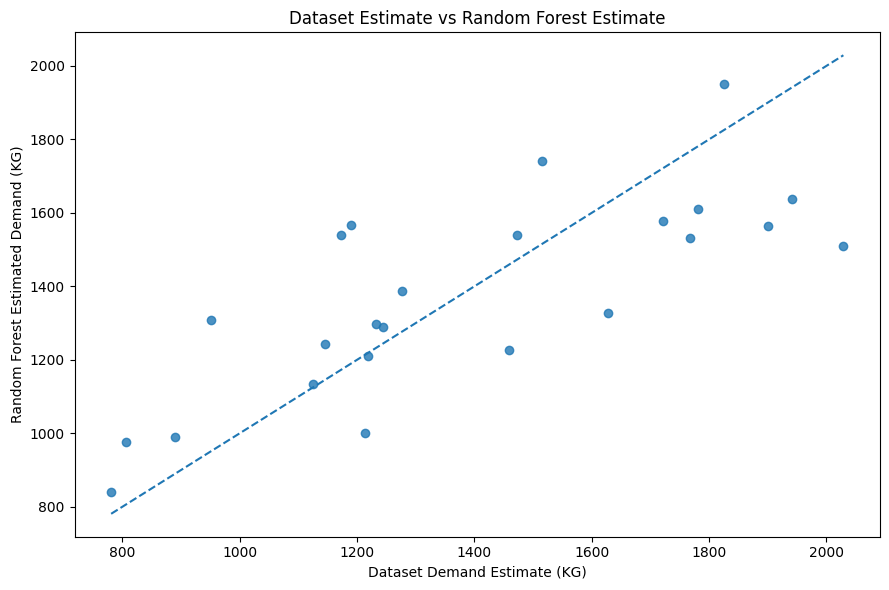


Demand Estimation Results Saved Successfully!

========== FAIR RETAIL PRICE ANALYSIS ==========
Average Traditional Retail Price: 88.1 INR/KG
Average Optimized Fair Retail Price: 58.19 INR/KG
Difference Between Average Prices: 29.91 INR/KG


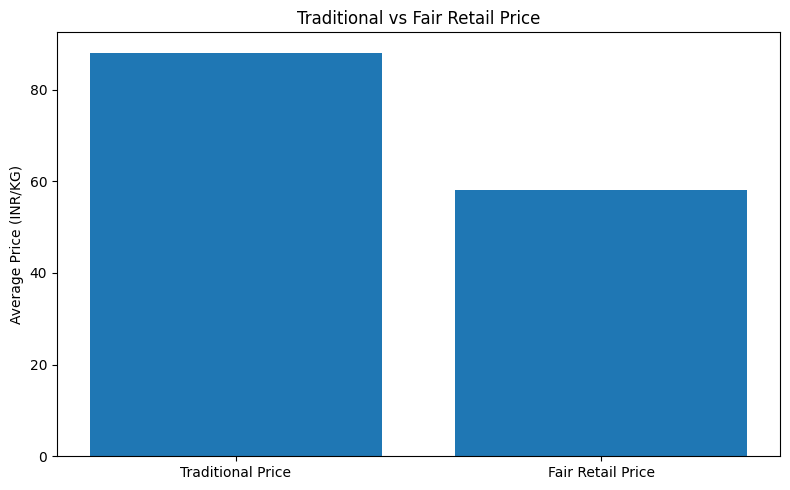


========== CONSUMER SAVINGS ANALYSIS ==========
Average Consumer Savings: 32.65 %


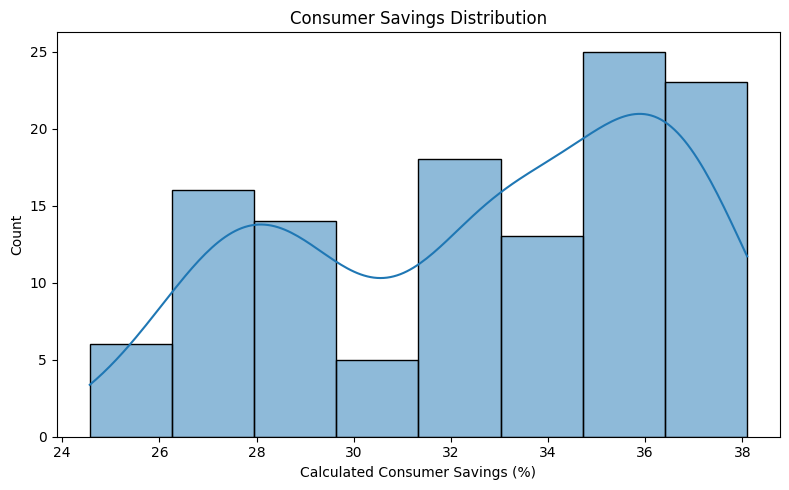


========== TRANSPORTATION COST ANALYSIS ==========
Average Transportation Cost: 3.6 INR/KG

Average Cost by Transportation Mode:
Transit_Mode
Mini Truck (Shared)    3.26
Standard Open Truck    3.28
Refrigerated Van       4.86
Name: Transit_Cost_INR_per_KG, dtype: float64


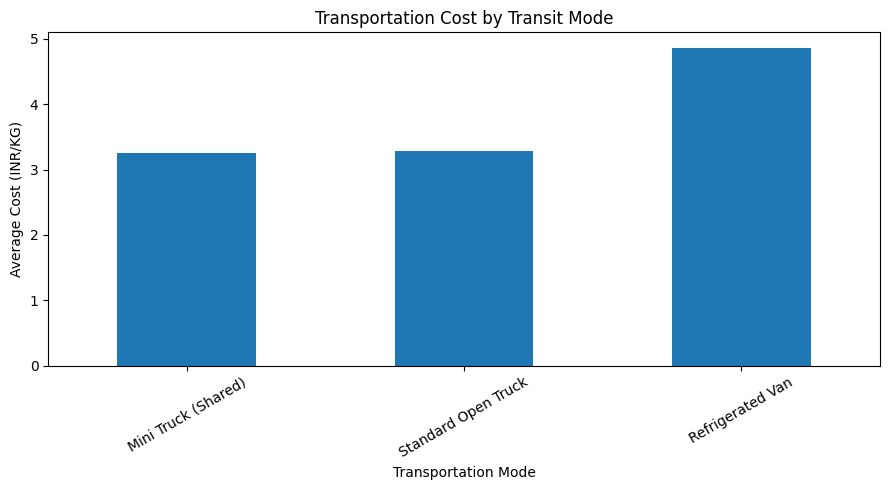


========== SPOILAGE ANALYSIS ==========
Average Baseline Spoilage: 2.14 %
Average Optimized Spoilage: 0.97 %
Average Spoilage Reduction: 1.17 percentage points


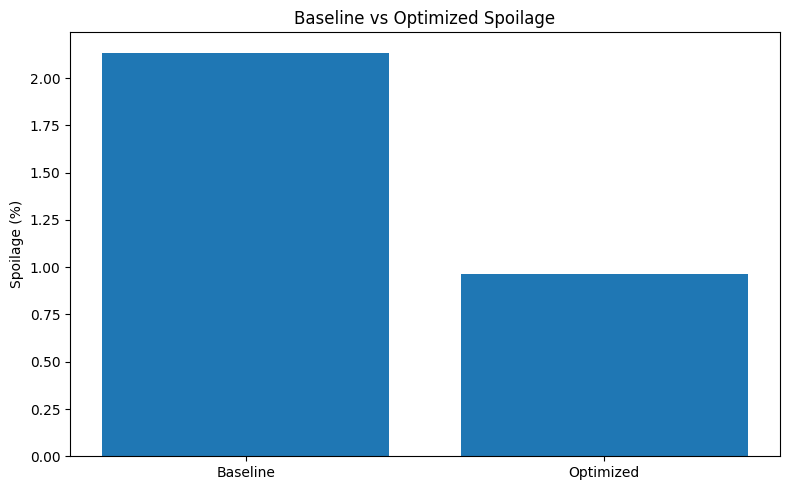


========== FARMER PAYOUT ANALYSIS ==========
Average Farmer Fair Payout: 34.52 INR/KG


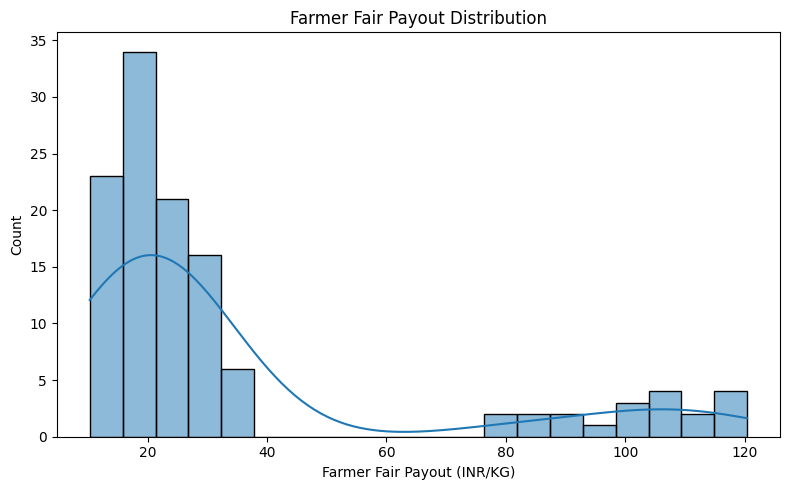


Machine Learning and Analysis Dataset Saved!

PART 3 COMPLETED SUCCESSFULLY!
RANDOM FOREST MODEL TRAINED!
DEMAND ESTIMATION COMPLETED!
PRICE ANALYSIS COMPLETED!
TRANSPORTATION ANALYSIS COMPLETED!
SPOILAGE ANALYSIS COMPLETED!


In [ ]:
# ============================================================
# PART 3: AI-BASED PRICE ANALYSIS AND MACHINE LEARNING
# PROJECT: SMART AGRICULTURAL SUPPLY CHAIN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("\n============================================")
print("PART 3: MACHINE LEARNING STARTED")
print("============================================")



data = df.copy()

print("\nDataset Shape:", data.shape)


if "Date" in data.columns:

    data["Date"] = pd.to_datetime(
        data["Date"],
        errors="coerce"
    )

    data["Month"] = data["Date"].dt.month

print("\nDataset Prepared Successfully!")


# IMPORTANT:
# This dataset already contains Predicted_Demand_KG.
# The model learns to estimate this existing dataset value.

target = "Predicted_Demand_KG"

if target not in data.columns:
    raise ValueError(
        "Target column Predicted_Demand_KG is missing!"
    )


possible_features = [
    "Commodity",
    "Harvest_Quantity_KG",
    "Distance_KM",
    "Transit_Mode",
    "Transit_Time_Hours",
    "Weather_Condition",
    "Shelf_Life_Days",
    "Farmer_Production_Cost_INR_per_KG",
    "Farmer_Fair_Payout_INR_per_KG",
    "Transit_Cost_INR_per_KG",
    "Handling_Storage_Cost_INR_per_KG",
    "Traditional_Wholesaler_Price_INR",
    "Traditional_Retail_Price_INR"
]

features = [
    column
    for column in possible_features
    if column in data.columns
]

if (
    "Month" in data.columns
    and data["Month"].nunique(dropna=True) > 1
):
    features.append("Month")

if len(features) == 0:
    raise ValueError("No suitable input features found!")

print("\nSelected Input Features:")
print(features)

print("\nTarget Variable:", target)


X = data[features].copy()

y = pd.to_numeric(
    data[target],
    errors="coerce"
)


valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

if len(X) < 5:
    raise ValueError(
        "Not enough valid records for machine learning."
    )


numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("\nData Preprocessing Completed!")


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

print("\nTraining Random Forest Model...")

model.fit(
    X_train,
    y_train
)

print("\nRandom Forest Model Trained Successfully!")


y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Dataset_Demand_Estimate_KG": y_test,
    "RF_Estimated_Demand_KG": y_pred
})

results.index.name = "Original_Record_Index"

print("\n========== DEMAND ESTIMATION RESULTS ==========")

print(results.head(10).round(2))


mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)

print("\n========== MODEL PERFORMANCE ==========")

print("Mean Absolute Error (MAE):", round(mae, 2))

print("Mean Squared Error (MSE):", round(mse, 2))

print("Root Mean Squared Error (RMSE):", round(rmse, 2))

print("R2 Score:", round(r2, 4))


plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.8
)

minimum_value = min(
    y_test.min(),
    y_pred.min()
)

maximum_value = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Dataset Demand Estimate (KG)")
plt.ylabel("Random Forest Estimated Demand (KG)")

plt.title("Dataset Estimate vs Random Forest Estimate")

plt.tight_layout()
plt.show()


results.to_csv(
    "agricultural_demand_predictions.csv"
)

print("\nDemand Estimation Results Saved Successfully!")


data["RF_Estimated_Demand_KG"] = np.nan

data.loc[
    results.index,
    "RF_Estimated_Demand_KG"
] = results["RF_Estimated_Demand_KG"]


print("\n========== FAIR RETAIL PRICE ANALYSIS ==========")

if (
    "Traditional_Retail_Price_INR" in data.columns
    and "Optimized_Fair_Retail_Price_INR" in data.columns
):

    traditional_price = data[
        "Traditional_Retail_Price_INR"
    ]

    optimized_price = data[
        "Optimized_Fair_Retail_Price_INR"
    ]

    average_traditional_price = traditional_price.mean()

    average_optimized_price = optimized_price.mean()

    average_price_difference = (
        average_traditional_price
        - average_optimized_price
    )

    print(
        "Average Traditional Retail Price:",
        round(average_traditional_price, 2),
        "INR/KG"
    )

    print(
        "Average Optimized Fair Retail Price:",
        round(average_optimized_price, 2),
        "INR/KG"
    )

    print(
        "Difference Between Average Prices:",
        round(average_price_difference, 2),
        "INR/KG"
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        ["Traditional Price", "Fair Retail Price"],
        [
            average_traditional_price,
            average_optimized_price
        ]
    )

    plt.title("Traditional vs Fair Retail Price")
    plt.ylabel("Average Price (INR/KG)")
    plt.tight_layout()
    plt.show()

else:
    print("Required retail price columns are not available.")


# STEP 12: CONSUMER SAVINGS ANALYSIS

print("\n========== CONSUMER SAVINGS ANALYSIS ==========")

if (
    "Traditional_Retail_Price_INR" in data.columns
    and "Optimized_Fair_Retail_Price_INR" in data.columns
):

    traditional = data["Traditional_Retail_Price_INR"]

    fair_price = data["Optimized_Fair_Retail_Price_INR"]

    data["Calculated_Consumer_Savings_Pct"] = np.where(
        traditional > 0,
        ((traditional - fair_price) / traditional) * 100,
        np.nan
    )

    average_consumer_savings = (
        data["Calculated_Consumer_Savings_Pct"].mean()
    )

    print(
        "Average Consumer Savings:",
        round(average_consumer_savings, 2),
        "%"
    )

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data["Calculated_Consumer_Savings_Pct"].dropna(),
        kde=True
    )

    plt.title("Consumer Savings Distribution")
    plt.xlabel("Calculated Consumer Savings (%)")
    plt.tight_layout()
    plt.show()


print("\n========== TRANSPORTATION COST ANALYSIS ==========")

if "Transit_Cost_INR_per_KG" in data.columns:

    average_transport_cost = (
        data["Transit_Cost_INR_per_KG"].mean()
    )

    print(
        "Average Transportation Cost:",
        round(average_transport_cost, 2),
        "INR/KG"
    )

    if "Transit_Mode" in data.columns:

        transport_analysis = data.groupby(
            "Transit_Mode"
        )["Transit_Cost_INR_per_KG"].mean().sort_values()

        print("\nAverage Cost by Transportation Mode:")
        print(transport_analysis.round(2))

        transport_analysis.plot(
            kind="bar",
            figsize=(9, 5)
        )

        plt.title("Transportation Cost by Transit Mode")
        plt.xlabel("Transportation Mode")
        plt.ylabel("Average Cost (INR/KG)")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


print("\n========== SPOILAGE ANALYSIS ==========")

if (
    "Baseline_Spoilage_Pct" in data.columns
    and "Optimized_Spoilage_Pct" in data.columns
):

    baseline_spoilage = data[
        "Baseline_Spoilage_Pct"
    ]

    optimized_spoilage = data[
        "Optimized_Spoilage_Pct"
    ]

    average_baseline_spoilage = baseline_spoilage.mean()

    average_optimized_spoilage = optimized_spoilage.mean()

    average_spoilage_reduction = (
        baseline_spoilage - optimized_spoilage
    ).mean()

    print(
        "Average Baseline Spoilage:",
        round(average_baseline_spoilage, 2),
        "%"
    )

    print(
        "Average Optimized Spoilage:",
        round(average_optimized_spoilage, 2),
        "%"
    )

    print(
        "Average Spoilage Reduction:",
        round(average_spoilage_reduction, 2),
        "percentage points"
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        ["Baseline", "Optimized"],
        [
            average_baseline_spoilage,
            average_optimized_spoilage
        ]
    )

    plt.title("Baseline vs Optimized Spoilage")
    plt.ylabel("Spoilage (%)")
    plt.tight_layout()
    plt.show()


print("\n========== FARMER PAYOUT ANALYSIS ==========")

if "Farmer_Fair_Payout_INR_per_KG" in data.columns:

    average_farmer_payout = (
        data["Farmer_Fair_Payout_INR_per_KG"].mean()
    )

    print(
        "Average Farmer Fair Payout:",
        round(average_farmer_payout, 2),
        "INR/KG"
    )

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data["Farmer_Fair_Payout_INR_per_KG"].dropna(),
        kde=True
    )

    plt.title("Farmer Fair Payout Distribution")
    plt.xlabel("Farmer Fair Payout (INR/KG)")
    plt.tight_layout()
    plt.show()


data.to_csv(
    "smart_agricultural_optimization_results.csv",
    index=False
)

print("\nMachine Learning and Analysis Dataset Saved!")


print("\n============================================")
print("PART 3 COMPLETED SUCCESSFULLY!")
print("RANDOM FOREST MODEL TRAINED!")
print("DEMAND ESTIMATION COMPLETED!")
print("PRICE ANALYSIS COMPLETED!")
print("TRANSPORTATION ANALYSIS COMPLETED!")
print("SPOILAGE ANALYSIS COMPLETED!")
print("============================================")


PART 4: FINAL PROJECT DASHBOARD

Final Dataset Loaded Successfully!
Total Records: 120
Total Columns: 27

========== PROJECT SUMMARY ==========
Total Records: 120
Total Commodities: 6

========== COMMODITY PERFORMANCE ==========

Commodity Distribution:
Commodity
Tomato         20
Potato         20
Onion          20
Cauliflower    20
Apple          20
Banana         20
Name: count, dtype: int64


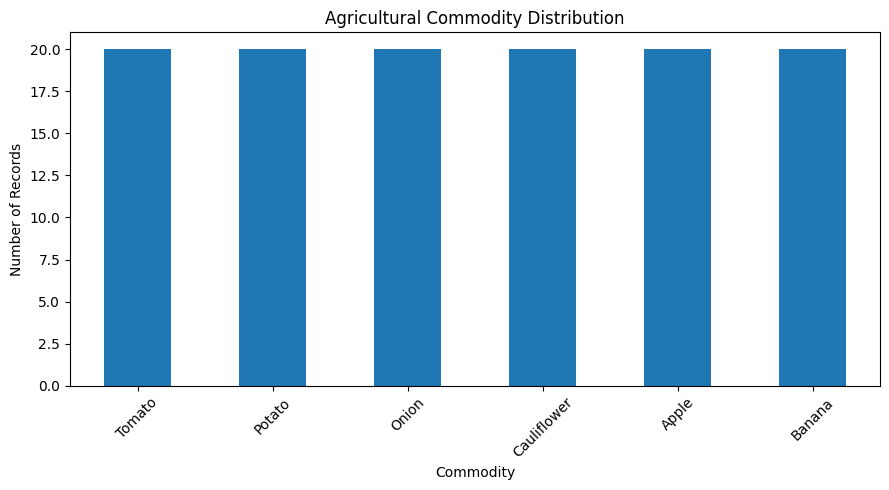


========== DEMAND AND HARVEST ANALYSIS ==========
Average Dataset Demand Estimate: 1347.59 KG
Average Harvest Quantity: 1187.14 KG


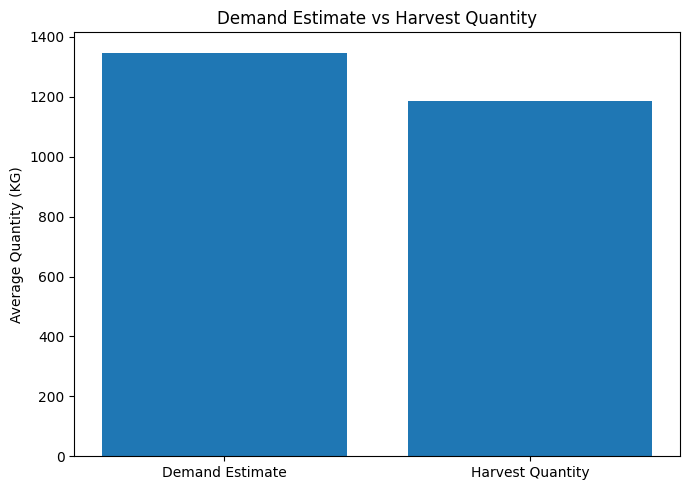


========== MACHINE LEARNING RESULTS ==========
Mean Absolute Error: 193.55
Mean Squared Error: 54894.83
Root Mean Squared Error: 234.3
R2 Score: 0.5807


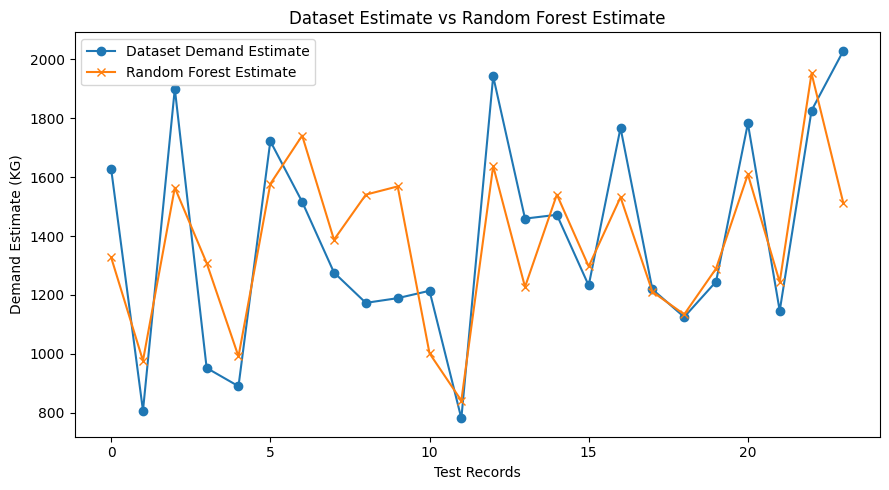


========== FARMER AND CONSUMER BENEFITS ==========
Average Traditional Retail Price: 88.1 INR/KG
Average Optimized Fair Retail Price: 58.19 INR/KG
Difference Between Average Prices: 29.91 INR/KG
Average Row-Wise Consumer Savings: 32.65 %


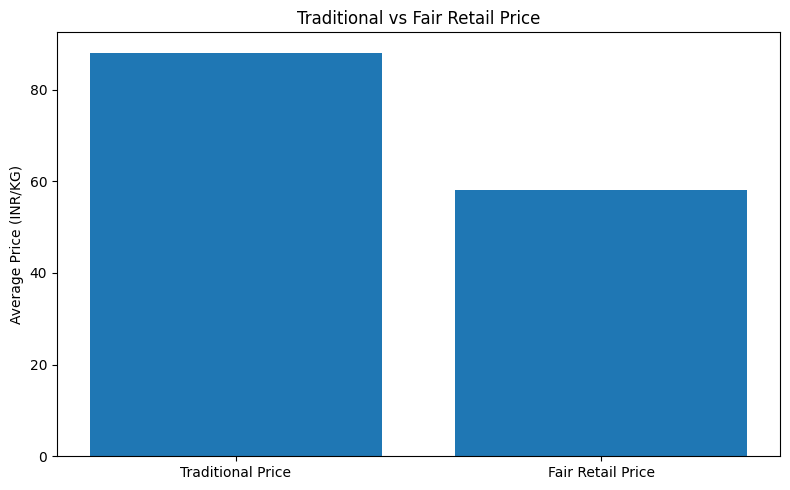


========== TRANSPORTATION PERFORMANCE ==========
Average Transportation Cost: 3.6 INR/KG

Transportation Mode Performance:
Transit_Mode
Mini Truck (Shared)    3.26
Standard Open Truck    3.28
Refrigerated Van       4.86
Name: Transit_Cost_INR_per_KG, dtype: float64


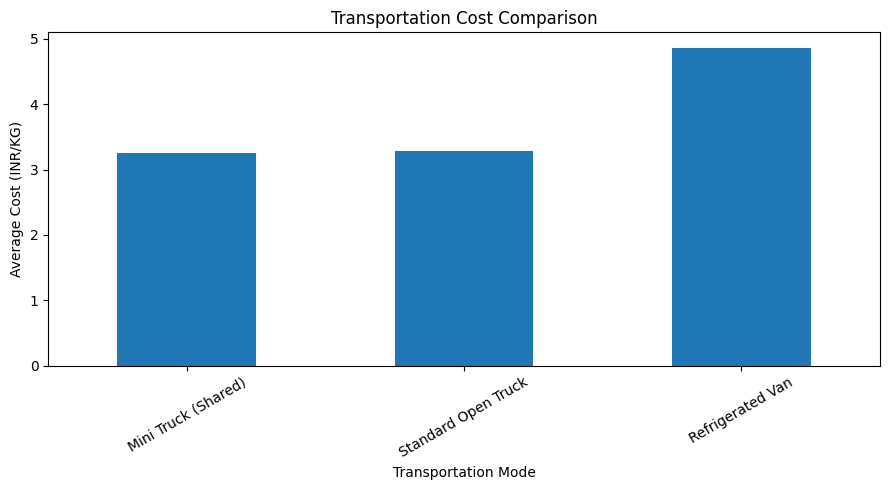


========== SPOILAGE REDUCTION RESULTS ==========
Average Baseline Spoilage: 2.14 %
Average Optimized Spoilage: 0.97 %
Spoilage Reduction: 1.17 percentage points


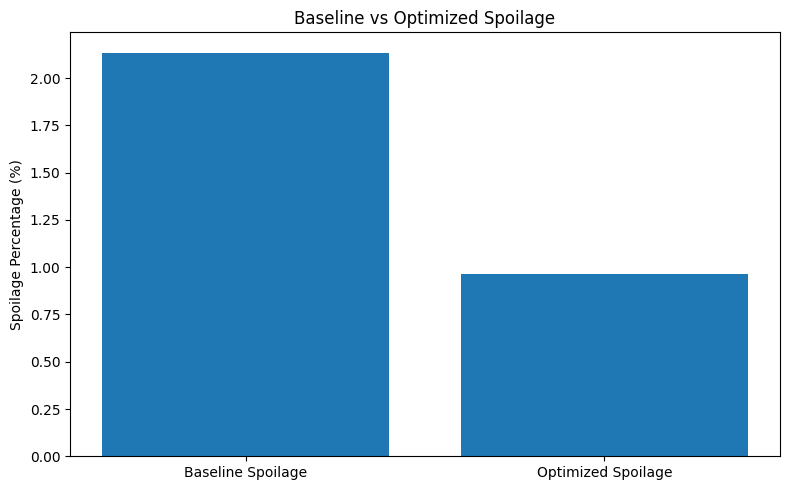


========== FARMER FAIR PAYOUT ==========
Average Farmer Fair Payout: 34.52 INR/KG

========== FINAL CORRELATION ANALYSIS ==========


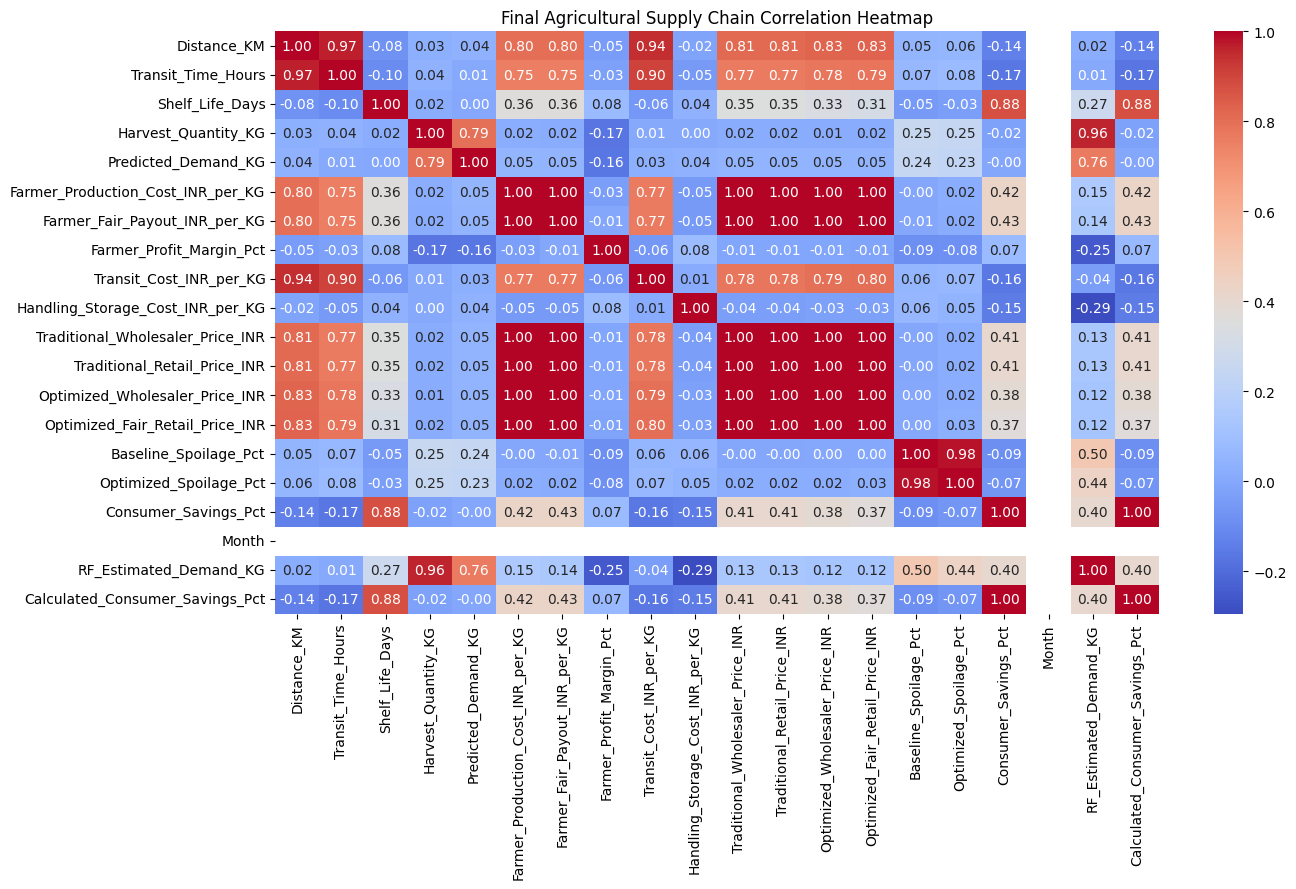


========== FINAL PROJECT DASHBOARD ==========
                 Performance Indicator     Value
                         Total Records  120.0000
                     Total Commodities    6.0000
          Average Demand Estimate (KG) 1347.5900
         Average Harvest Quantity (KG) 1187.1400
    Average Traditional Price (INR/KG)   88.1000
    Average Fair Retail Price (INR/KG)   58.1900
     Average Price Difference (INR/KG)   29.9100
          Average Consumer Savings (%)   32.6500
       Average Transport Cost (INR/KG)    3.6000
                 Baseline Spoilage (%)    2.1400
                Optimized Spoilage (%)    0.9700
Spoilage Reduction (Percentage Points)    1.1700
   Average Farmer Fair Payout (INR/KG)   34.5200
                             Model MAE  193.5500
                            Model RMSE  234.3000
                        Model R2 Score    0.5807

========== GENERATING FINAL PROJECT REPORT ==========
Final Project Report Generated Successfully!

Final Dataset Saved

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SMART AGRICULTURAL SUPPLY CHAIN
ALL FOUR PROJECT PARTS COMPLETED!
DATA ANALYSIS COMPLETED!
MACHINE LEARNING COMPLETED!
FINAL DASHBOARD GENERATED!
PROJECT SUCCESSFULLY COMPLETED!


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("\n============================================")
print("PART 4: FINAL PROJECT DASHBOARD")
print("============================================")


if "data" in globals():
    final_data = data.copy()
else:
    final_data = df.copy()

print("\nFinal Dataset Loaded Successfully!")

print("Total Records:", len(final_data))
print("Total Columns:", len(final_data.columns))


print("\n========== PROJECT SUMMARY ==========")

total_records = len(final_data)

total_commodities = (
    final_data["Commodity"].nunique()
    if "Commodity" in final_data.columns
    else 0
)

print("Total Records:", total_records)

print("Total Commodities:", total_commodities)


print("\n========== COMMODITY PERFORMANCE ==========")

if "Commodity" in final_data.columns:

    commodity_count = final_data[
        "Commodity"
    ].value_counts()

    print("\nCommodity Distribution:")
    print(commodity_count)

    plt.figure(figsize=(9, 5))

    commodity_count.plot(kind="bar")

    plt.title("Agricultural Commodity Distribution")
    plt.xlabel("Commodity")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


print("\n========== DEMAND AND HARVEST ANALYSIS ==========")

average_demand = np.nan
average_harvest = np.nan

if "Predicted_Demand_KG" in final_data.columns:

    average_demand = final_data[
        "Predicted_Demand_KG"
    ].mean()

    print(
        "Average Dataset Demand Estimate:",
        round(average_demand, 2),
        "KG"
    )

if "Harvest_Quantity_KG" in final_data.columns:

    average_harvest = final_data[
        "Harvest_Quantity_KG"
    ].mean()

    print(
        "Average Harvest Quantity:",
        round(average_harvest, 2),
        "KG"
    )

if pd.notna(average_demand) and pd.notna(average_harvest):

    plt.figure(figsize=(7, 5))

    plt.bar(
        ["Demand Estimate", "Harvest Quantity"],
        [average_demand, average_harvest]
    )

    plt.title("Demand Estimate vs Harvest Quantity")
    plt.ylabel("Average Quantity (KG)")
    plt.tight_layout()
    plt.show()


print("\n========== MACHINE LEARNING RESULTS ==========")

ml_metrics_available = all(
    name in globals()
    for name in ["mae", "mse", "rmse", "r2"]
)

if ml_metrics_available:

    print("Mean Absolute Error:", round(mae, 2))

    print("Mean Squared Error:", round(mse, 2))

    print("Root Mean Squared Error:", round(rmse, 2))

    print("R2 Score:", round(r2, 4))

    if "results" in globals():

        plt.figure(figsize=(9, 5))

        plt.plot(
            results["Dataset_Demand_Estimate_KG"].values,
            label="Dataset Demand Estimate",
            marker="o"
        )

        plt.plot(
            results["RF_Estimated_Demand_KG"].values,
            label="Random Forest Estimate",
            marker="x"
        )

        plt.title("Dataset Estimate vs Random Forest Estimate")
        plt.xlabel("Test Records")
        plt.ylabel("Demand Estimate (KG)")
        plt.legend()
        plt.tight_layout()
        plt.show()

else:

    print("Machine Learning results are not available.")


print("\n========== FARMER AND CONSUMER BENEFITS ==========")

traditional_price = np.nan
optimized_price = np.nan
average_price_difference = np.nan
consumer_savings = np.nan

if (
    "Traditional_Retail_Price_INR" in final_data.columns
    and "Optimized_Fair_Retail_Price_INR" in final_data.columns
):

    traditional_price = final_data[
        "Traditional_Retail_Price_INR"
    ].mean()


    optimized_price = final_data[
        "Optimized_Fair_Retail_Price_INR"
    ].mean()

    average_price_difference = (
        traditional_price - optimized_price
    )

    print(
        "Average Traditional Retail Price:",
        round(traditional_price, 2),
        "INR/KG"
    )

    print(
        "Average Optimized Fair Retail Price:",
        round(optimized_price, 2),
        "INR/KG"
    )

    print(
        "Difference Between Average Prices:",
        round(average_price_difference, 2),
        "INR/KG"
    )



    row_savings = np.where(
        final_data["Traditional_Retail_Price_INR"] > 0,
        (
            (
                final_data["Traditional_Retail_Price_INR"]
                - final_data["Optimized_Fair_Retail_Price_INR"]
            )
            / final_data["Traditional_Retail_Price_INR"]
        ) * 100,
        np.nan
    )

    consumer_savings = np.nanmean(row_savings)

    print(
        "Average Row-Wise Consumer Savings:",
        round(consumer_savings, 2),
        "%"
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        ["Traditional Price", "Fair Retail Price"],
        [traditional_price, optimized_price]
    )

    plt.title("Traditional vs Fair Retail Price")
    plt.ylabel("Average Price (INR/KG)")
    plt.tight_layout()
    plt.show()


print("\n========== TRANSPORTATION PERFORMANCE ==========")

average_transport_cost = np.nan

if "Transit_Cost_INR_per_KG" in final_data.columns:

    average_transport_cost = final_data[
        "Transit_Cost_INR_per_KG"
    ].mean()

    print(
        "Average Transportation Cost:",
        round(average_transport_cost, 2),
        "INR/KG"
    )

    if "Transit_Mode" in final_data.columns:

        transport_data = final_data.groupby(
            "Transit_Mode"
        )["Transit_Cost_INR_per_KG"].mean().sort_values()

        print("\nTransportation Mode Performance:")
        print(transport_data.round(2))

        transport_data.plot(
            kind="bar",
            figsize=(9, 5)
        )

        plt.title("Transportation Cost Comparison")
        plt.xlabel("Transportation Mode")
        plt.ylabel("Average Cost (INR/KG)")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


print("\n========== SPOILAGE REDUCTION RESULTS ==========")

baseline_spoilage = np.nan
optimized_spoilage = np.nan
spoilage_reduction = np.nan

if (
    "Baseline_Spoilage_Pct" in final_data.columns
    and "Optimized_Spoilage_Pct" in final_data.columns
):

    baseline_spoilage = final_data[
        "Baseline_Spoilage_Pct"
    ].mean()

    optimized_spoilage = final_data[
        "Optimized_Spoilage_Pct"
    ].mean()

    spoilage_reduction = (
        baseline_spoilage - optimized_spoilage
    )

    print(
        "Average Baseline Spoilage:",
        round(baseline_spoilage, 2),
        "%"
    )

    print(
        "Average Optimized Spoilage:",
        round(optimized_spoilage, 2),
        "%"
    )

    print(
        "Spoilage Reduction:",
        round(spoilage_reduction, 2),
        "percentage points"
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        ["Baseline Spoilage", "Optimized Spoilage"],
        [baseline_spoilage, optimized_spoilage]
    )

    plt.title("Baseline vs Optimized Spoilage")
    plt.ylabel("Spoilage Percentage (%)")
    plt.tight_layout()
    plt.show()


print("\n========== FARMER FAIR PAYOUT ==========")

average_farmer_payout = np.nan

if "Farmer_Fair_Payout_INR_per_KG" in final_data.columns:

    average_farmer_payout = final_data[
        "Farmer_Fair_Payout_INR_per_KG"
    ].mean()

    print(
        "Average Farmer Fair Payout:",
        round(average_farmer_payout, 2),
        "INR/KG"
    )


# STEP 10: FINAL CORRELATION ANALYSIS

print("\n========== FINAL CORRELATION ANALYSIS ==========")

numerical_data = final_data.select_dtypes(
    include=["number"]
).copy()

if "Batch_ID" in numerical_data.columns:

    numerical_data = numerical_data.drop(
        columns=["Batch_ID"]
    )

if numerical_data.shape[1] > 1:

    plt.figure(figsize=(14, 9))

    sns.heatmap(
        numerical_data.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Final Agricultural Supply Chain Correlation Heatmap")
    plt.tight_layout()
    plt.show()


# STEP 11: GENERATE FINAL PERFORMANCE DASHBOARD

print("\n========== FINAL PROJECT DASHBOARD ==========")

dashboard = {
    "Total Records": total_records,
    "Total Commodities": total_commodities
}

# Add demand and harvest KPIs

if pd.notna(average_demand):
    dashboard["Average Demand Estimate (KG)"] = round(
        average_demand, 2
    )

if pd.notna(average_harvest):
    dashboard["Average Harvest Quantity (KG)"] = round(
        average_harvest, 2
    )

# Add price KPIs

if pd.notna(traditional_price):
    dashboard["Average Traditional Price (INR/KG)"] = round(
        traditional_price, 2
    )

if pd.notna(optimized_price):
    dashboard["Average Fair Retail Price (INR/KG)"] = round(
        optimized_price, 2
    )

if pd.notna(average_price_difference):
    dashboard["Average Price Difference (INR/KG)"] = round(
        average_price_difference, 2
    )

if pd.notna(consumer_savings):
    dashboard["Average Consumer Savings (%)"] = round(
        consumer_savings, 2
    )

# Add transportation KPI

if pd.notna(average_transport_cost):
    dashboard["Average Transport Cost (INR/KG)"] = round(
        average_transport_cost, 2
    )

# Add spoilage KPIs

if pd.notna(baseline_spoilage):
    dashboard["Baseline Spoilage (%)"] = round(
        baseline_spoilage, 2
    )

if pd.notna(optimized_spoilage):
    dashboard["Optimized Spoilage (%)"] = round(
        optimized_spoilage, 2
    )

if pd.notna(spoilage_reduction):
    dashboard["Spoilage Reduction (Percentage Points)"] = round(
        spoilage_reduction, 2
    )

# Add farmer payout KPI

if pd.notna(average_farmer_payout):
    dashboard["Average Farmer Fair Payout (INR/KG)"] = round(
        average_farmer_payout, 2
    )

# Add ML metrics

if ml_metrics_available:

    dashboard["Model MAE"] = round(mae, 2)

    dashboard["Model RMSE"] = round(rmse, 2)

    dashboard["Model R2 Score"] = round(r2, 4)


dashboard_df = pd.DataFrame(
    list(dashboard.items()),
    columns=[
        "Performance Indicator",
        "Value"
    ]
)

print(dashboard_df.to_string(index=False))


# STEP 12: GENERATE FINAL PROJECT REPORT

print("\n========== GENERATING FINAL PROJECT REPORT ==========")

report = []

report.append("SMART AGRICULTURAL SUPPLY CHAIN")
report.append("FINAL PROJECT ANALYSIS REPORT")
report.append("=" * 50)

report.append("\nPROJECT SUMMARY")

for key, value in dashboard.items():

    report.append(f"{key}: {value}")


report.append("\nMACHINE LEARNING DETAILS")

report.append(
    "Algorithm Used: Random Forest Regressor"
)

report.append(
    "Target Variable: Predicted_Demand_KG"
)

report.append(
    "Target Meaning: Existing dataset demand estimate"
)

report.append(
    "The model predicts the dataset's pre-existing demand estimate, "
    "not independently verified actual future demand."
)


report.append("\nPROJECT ANALYSIS DETAILS")

report.append(
    "Price and spoilage comparisons use values already present "
    "in the supplied dataset."
)

report.append(
    "These comparisons are not the output of a newly developed "
    "price or spoilage optimization algorithm."
)

report.append(
    "Harvest quantity is compared with estimated demand; "
    "it is not treated as confirmed market supply."
)

report.append(
    "The dataset covers a limited date range, so seasonal "
    "conclusions should not be drawn from it."
)

report.append("\n" + "=" * 50)

report.append("PROJECT ANALYSIS COMPLETED SUCCESSFULLY!")


with open(
    "Smart_Agricultural_Supply_Chain_Report.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write("\n".join(report))

print("Final Project Report Generated Successfully!")


# STEP 13: SAVE FINAL DATASETS

final_data.to_csv(
    "Final_Smart_Agricultural_Supply_Chain.csv",
    index=False
)

dashboard_df.to_csv(
    "Final_Project_Dashboard.csv",
    index=False
)

print("\nFinal Dataset Saved!")
print("Dashboard CSV Saved!")
print("Project Report Saved!")


# STEP 14: DOWNLOAD FINAL PROJECT FILES

from google.colab import files

print("\nDownloading Final Project Files...")

files.download(
    "Final_Smart_Agricultural_Supply_Chain.csv"
)

files.download(
    "Final_Project_Dashboard.csv"
)

files.download(
    "Smart_Agricultural_Supply_Chain_Report.txt"
)


# ============================================================
# FINAL PROJECT COMPLETED
# ============================================================

print("\n============================================")
print("SMART AGRICULTURAL SUPPLY CHAIN")
print("ALL FOUR PROJECT PARTS COMPLETED!")
print("DATA ANALYSIS COMPLETED!")
print("MACHINE LEARNING COMPLETED!")
print("FINAL DASHBOARD GENERATED!")
print("PROJECT SUCCESSFULLY COMPLETED!")
print("============================================")